In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime

# Loading files

In [26]:
df_patient_info = pd.read_csv('../T1DiabetesGranada/Patient_info.csv', dtype={'Number_of_days_with_measures':np.int32, 'Number_of_measurements':np.int32})
df_glucose_measurements = pd.read_csv('../T1DiabetesGranada/Glucose_measurements.csv', dtype={'Measurement' : np.int16}, nrows=1000)
df_biochemical_parameters = pd.read_csv('../T1DiabetesGranada/Biochemical_parameters.csv')
df_diagnostics = pd.read_csv('../T1DiabetesGranada/Diagnostics.csv')

In [27]:
df_patient_info.name = 'Patient_info.csv'
df_glucose_measurements.name = 'Glucose_measurements.csv'
df_biochemical_parameters.name = 'Biochemical_parameters.csv'
df_diagnostics.name = 'Diagnostics.csv'

In [28]:
datasets_list = [df_patient_info, df_glucose_measurements, df_biochemical_parameters, df_diagnostics]
datasets_list.reverse()

# General files description

In [29]:
general_table = pd.DataFrame(columns=['File Name', 'Number of instances', 'Number of features', 'Size (Bytes)', 'Lost values'])
for current_df in datasets_list:
    current_dic = {'File Name': current_df.name,
                   'Number of instances': current_df.shape[0],
                   'Number of features': current_df.shape[1],
                   'Size (Bytes)': current_df.size,
                   'Lost values': 'Yes' if current_df.isnull().values.any() else 'No'
                }
    series_values = pd.Series(current_dic)
    general_table = pd.concat([pd.DataFrame([series_values]), general_table])

general_table

,File Name,Number of instances,Number of features,Size (Bytes),Lost values
0,Patient_info.csv,736,11,8096,Yes
0,Glucose_measurements.csv,1000,4,4000,No
0,Biochemical_parameters.csv,87482,4,349928,No
0,Diagnostics.csv,1757,3,5271,No


# ***Patient_info.csv***

## Distribution of the age of the patients at the start of the data collection (January 6th, 2018).


In [30]:
def get_age_in(birth_year:str, in_year:str) -> int:
    """
    From a string (in YYYY) get the age of the patient in a given date
    :param birth_year:  year of birth of the patient as a string
    :param in_year: year from where the age will be calculated
    :return: An integer with the age of the patient
    """
    birth_year_int = int(birth_year)
    in_year_int = int(in_year)

    age = in_year_int - birth_year_int

    return age

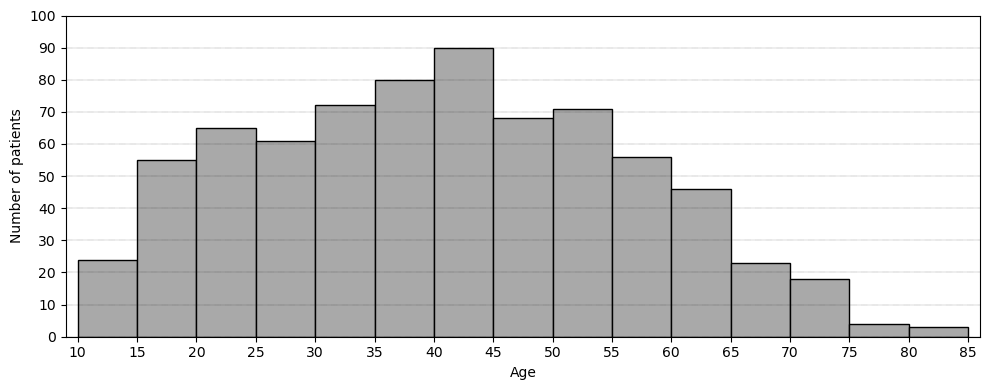

In [31]:
df_patient_info['Age'] = df_patient_info.apply(lambda row: get_age_in(row['Birth_year'], '2017'),axis=1)
series_age = df_patient_info['Age']

fig = plt.figure(figsize =(10, 4), tight_layout = True)
ax = fig.add_subplot(111)
bin_set = np.arange(10,86,5)
n, bins, patches = ax.hist(series_age, histtype='bar', align='mid', bins=bin_set, color='darkgray', edgecolor = "black")
ax.grid(axis='y', linestyle=':', linewidth='0.3', color='black')

bins_x = np.insert(bin_set, 0, [0 , 5])
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_ticks_values = np.arange(0,101,10)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

lim = ax.set_xlim(xmin=9, xmax=86)

y_title = ax.set_ylabel('Number of patients')
x_title = ax.set_xlabel('Age')

## Stats

In [32]:
print('Min age: ', series_age.min())
print('Max age: ', series_age.max())
print()
print(series_age.describe())

Min age:  12
Max age:  81

count    736.000000
mean      40.336957
std       15.772724
min       12.000000
25%       27.000000
50%       40.000000
75%       52.000000
max       81.000000
Name: Age, dtype: float64


## Number of patients by number of days with glucose levels measurements

### Stats

In [33]:
print(df_patient_info['Number_of_days_with_measures'].describe())

count     736.000000
mean      350.244565
std       284.146680
min         8.000000
25%       122.000000
50%       286.000000
75%       525.000000
max      1463.000000
Name: Number_of_days_with_measures, dtype: float64


### Bar graph

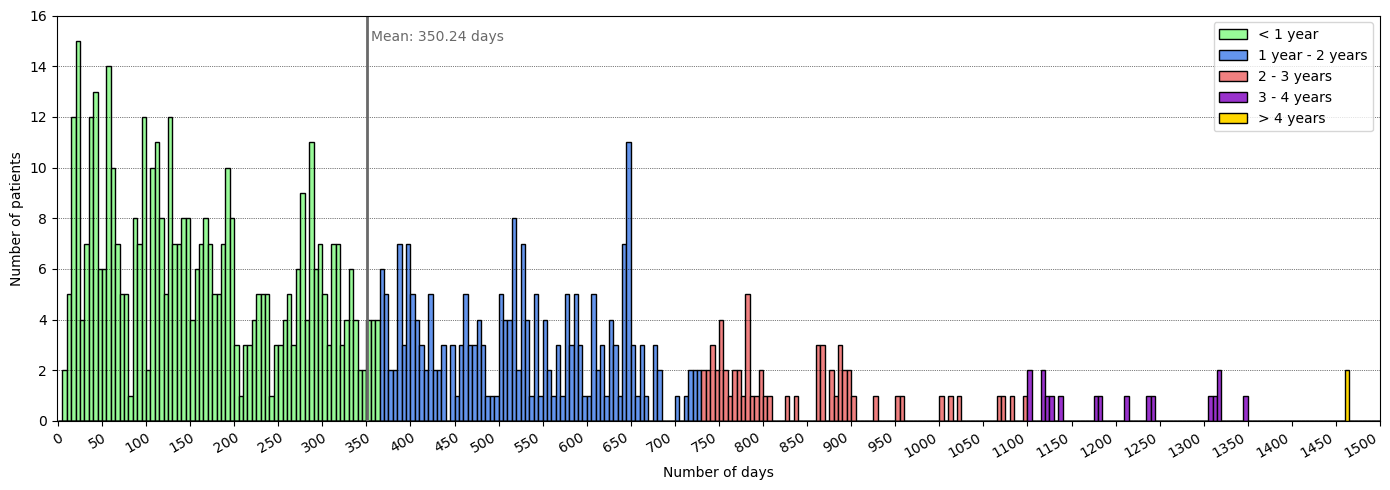

In [34]:
fig = plt.figure(figsize =(14, 5), tight_layout = True)
ax = fig.add_subplot(111)

bin_set = np.arange(0,1501,5)

n, bins, patches = ax.hist(df_patient_info[df_patient_info['Number_of_days_with_measures'] < 365]['Number_of_days_with_measures'], histtype='bar', align='mid', color='palegreen', bins=bin_set, edgecolor = "black", label='< 1 year')
n, bins, patches = ax.hist(df_patient_info[(df_patient_info['Number_of_days_with_measures'] >= 365) & (df_patient_info['Number_of_days_with_measures'] <= 730)]['Number_of_days_with_measures'], histtype='bar', align='mid', color='cornflowerblue', bins=bin_set, edgecolor = "black", label='1 year - 2 years')
n, bins, patches = ax.hist(df_patient_info[(df_patient_info['Number_of_days_with_measures'] > 730) & (df_patient_info['Number_of_days_with_measures'] <= 1095)]['Number_of_days_with_measures'], histtype='bar', align='mid', color='lightcoral', bins=bin_set, edgecolor = "black", label='2 - 3 years')
n, bins, patches = ax.hist(df_patient_info[(df_patient_info['Number_of_days_with_measures'] > 1095) & (df_patient_info['Number_of_days_with_measures'] <= 1460)]['Number_of_days_with_measures'], histtype='bar', align='mid', color='darkorchid', bins=bin_set, edgecolor = "black", label='3 - 4 years')
n, bins, patches = ax.hist(df_patient_info[(df_patient_info['Number_of_days_with_measures'] > 1460)]['Number_of_days_with_measures'], histtype='bar', align='mid', color='gold', bins=bin_set, edgecolor = "black", label='> 4 years')

plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

average_days_with_measures = df_patient_info['Number_of_days_with_measures'].mean()

average_days_with_measures = df_patient_info['Number_of_days_with_measures'].mean()

ax.axvline(average_days_with_measures, color='dimgray', linestyle='solid', linewidth=2)
ax.text(average_days_with_measures + 5, 15, f'Mean: {average_days_with_measures:.2f} days', color='dimgray')

ax.legend()

bins_x = np.arange(0,1501,50)
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_title = ax.set_ylabel('Number of patients')
x_title = ax.set_xlabel('Number of days')

lim_x = ax.set_xlim(xmin=-1, xmax=1500)
lim_y = ax.set_ylim(ymax=16)

In [35]:
print('Min Number_of_days_with_measures: ', df_patient_info['Number_of_days_with_measures'].min())
print('Max Number_of_days_with_measures: ', df_patient_info['Number_of_days_with_measures'].max())

Min Number_of_days_with_measures:  8
Max Number_of_days_with_measures:  1463


## Total days with measurements

In [36]:
print(df_patient_info['Number_of_days_with_measures'].sum())

257780


## Number of measurements stats

In [37]:
print(df_patient_info['Number_of_measurements'].describe())

count       736.000000
mean      30802.951087
std       25704.868842
min         400.000000
25%       10673.000000
50%       25002.500000
75%       45686.500000
max      137292.000000
Name: Number_of_measurements, dtype: float64


## Number of biochemical parameters stats

In [38]:
print(df_patient_info['Number_of_biochemical_parameters'].describe())

count    723.000000
mean     120.998617
std       87.834182
min        4.000000
25%       75.000000
50%      107.000000
75%      137.000000
max      846.000000
Name: Number_of_biochemical_parameters, dtype: float64


## Number of diagnostics stats

In [39]:
print(df_patient_info['Number_of_diagnostics'].describe())

count    511.000000
mean       3.438356
std        2.946519
min        1.000000
25%        1.000000
50%        3.000000
75%        4.000000
max       24.000000
Name: Number_of_diagnostics, dtype: float64


# ***Glucose_measurements.csv***

## Measurement

### Data distribution of the glucose levels measurements

#### Stats

In [40]:
print(df_glucose_measurements['Measurement'].describe())

count    1000.000000
mean      143.923000
std        58.750666
min        40.000000
25%       101.000000
50%       141.000000
75%       178.000000
max       379.000000
Name: Measurement, dtype: float64


#### Plot

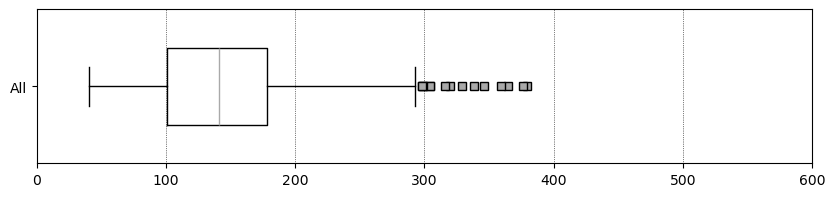

In [41]:
darkgray_square = dict(markerfacecolor='darkgray', marker='s')

fig, ax = plt.subplots(figsize=(10,2))

bp = ax.boxplot(df_glucose_measurements['Measurement'], vert=False, flierprops=darkgray_square, widths=0.5)

for median in bp['medians']:
    median.set_color('darkgray')

x_ticks_values = np.arange(0, 601, 100)
x_ticks_labels = list(map(str, x_ticks_values))
x_ticks = ax.xaxis.set_ticks(x_ticks_values)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_labels = ax.yaxis.set_ticklabels(['All'])

ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')

In [42]:
for key in bp:
    print(f'{key}: {[item.get_xdata() for item in bp[key]]}\n')

whiskers: [array([101.,  40.]), array([178., 293.])]

caps: [array([40, 40], dtype=int16), array([293, 293], dtype=int16)]

boxes: [array([101., 101., 178., 178., 101.])]

medians: [array([141., 141.])]

fliers: [array([304, 329, 346, 365, 379, 376, 359, 338, 320, 304, 299, 298, 316,
       298], dtype=int16)]

means: []



### Data distribution of the glucose levels measurements by sex

In [43]:
def remove_patients_by_ID_list_from_df(remove_list: pd.Series, df_source: pd.DataFrame) -> pd.DataFrame:
    """
    From a continuous glucose dataframe remove a list of patients and return the remaning rows
    :param remove_list: List o patients IDs to remove from the dataframe
    :param df_source: Dataframe from where to remove the patients IDs
    :return: The dataframe without the patients in @remove_list
    """
    if remove_list.empty:
        return df_source

    id_column = df_source.columns[0] # The ID must be the first column of the dataframe
    filt = True
    for current_patient in remove_list:
        filt = (filt & (df_source[id_column] != current_patient)) # On each iteration find the intersection between the current
                                                                 # boolean array and the cumulated one (In the first iteration is just 'True')

    df_result = df_source[filt] # Applying the created filter
    df_result.reset_index(inplace=True, drop=True)

    return df_result

In [44]:
def leave_patients_by_ID_list_from_df(leave_list: pd.Series, df_source: pd.DataFrame) -> pd.DataFrame:
    """
    From a continuous glucose dataframe return the dataframe with just the patient from the list
    :param leave_list: List o patients IDs to leave in the dataframe
    :param df_source: Dataframe from where to remove the patients IDs
    :return: The dataframe with just the patients in @leave_list
    """
    if leave_list.empty:
        return df_source

    id_column = df_source.columns[0] # The ID must be the first column of the dataframe
    filt = False
    for current_patient in leave_list:
        filt = (filt | (df_source[id_column] == current_patient)) # On each iteration find the disjunction between the current
                                                                 # boolean array and the cumulated one (In the first iteration is just 'False')

    df_result = df_source[filt] # Applying the created filter negated
    df_result.reset_index(inplace=True, drop=True)

    return df_result

In [45]:
male_patient_ID_series = df_patient_info[df_patient_info['Sex'] == 'M']['Patient_ID'] # IDs of the male patients
female_patient_ID_series = df_patient_info[df_patient_info['Sex'] == 'F']['Patient_ID'] # IDs of the female patients

In [46]:
df_glucose_masculine = leave_patients_by_ID_list_from_df(leave_list=male_patient_ID_series, df_source=df_glucose_measurements)
print(df_glucose_masculine.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        1000 non-null   object
 1   Measurement_date  1000 non-null   object
 2   Measurement_time  1000 non-null   object
 3   Measurement       1000 non-null   int16 
dtypes: int16(1), object(3)
memory usage: 25.5+ KB
None


In [47]:
df_glucose_female = leave_patients_by_ID_list_from_df(leave_list=female_patient_ID_series, df_source=df_glucose_measurements)
print(df_glucose_female.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        0 non-null      object
 1   Measurement_date  0 non-null      object
 2   Measurement_time  0 non-null      object
 3   Measurement       0 non-null      int16 
dtypes: int16(1), object(3)
memory usage: 132.0+ bytes
None


#### Box plot

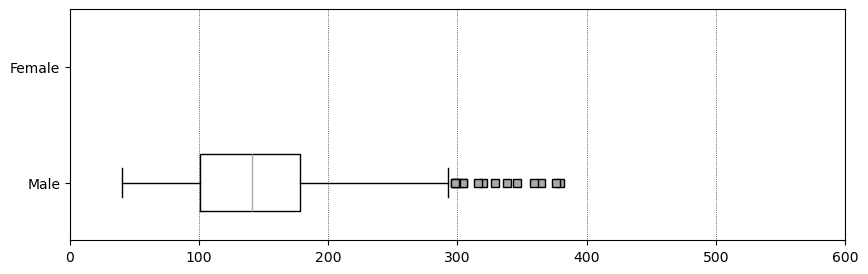

In [48]:
sex_plot_data = [df_glucose_masculine['Measurement'], df_glucose_female['Measurement']]
darkgray_square = dict(markerfacecolor='darkgray', marker='s')

fig, ax = plt.subplots(figsize=(10,3))

bp = ax.boxplot(sex_plot_data, vert=False, flierprops=darkgray_square, widths=0.5)

for median in bp['medians']:
    median.set_color('darkgray')

x_ticks_values = np.arange(0, 601, 100)
x_ticks_labels = list(map(str, x_ticks_values))
x_ticks = ax.xaxis.set_ticks(x_ticks_values)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_labels = ax.yaxis.set_ticklabels(['Male', 'Female'])

ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')

plt.show()

### Data distribution of the glucose levels measurements by age

In [49]:
# Creating patient age ranks
young_patient_ID_series = df_patient_info[df_patient_info['Age'] < 31]['Patient_ID'] # Patients with age < 31
young_adult_patient_ID_series = df_patient_info[(df_patient_info['Age'] >= 31) & (df_patient_info['Age'] < 46)]['Patient_ID'] # Patients with 31 <= age < 46
adult_patient_ID_series = df_patient_info[(df_patient_info['Age'] >= 46) & (df_patient_info['Age'] < 66)]['Patient_ID'] # Patients with 46 <= age < 65
elders_patient_ID_series = df_patient_info[(df_patient_info['Age'] >= 66)]['Patient_ID'] # Patients with  age >= 66

In [50]:
df_glucose_young = leave_patients_by_ID_list_from_df(leave_list=young_patient_ID_series, df_source=df_glucose_measurements) # Glucose_measurement subset dataframe with young patients
print(df_glucose_young.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        0 non-null      object
 1   Measurement_date  0 non-null      object
 2   Measurement_time  0 non-null      object
 3   Measurement       0 non-null      int16 
dtypes: int16(1), object(3)
memory usage: 132.0+ bytes
None


In [51]:
df_glucose_young_adult = leave_patients_by_ID_list_from_df(leave_list=young_adult_patient_ID_series, df_source=df_glucose_measurements) # Glucose_measurement subset dataframe with young adult patients
print(df_glucose_young_adult.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        0 non-null      object
 1   Measurement_date  0 non-null      object
 2   Measurement_time  0 non-null      object
 3   Measurement       0 non-null      int16 
dtypes: int16(1), object(3)
memory usage: 132.0+ bytes
None


In [52]:
df_glucose_adult = leave_patients_by_ID_list_from_df(leave_list=adult_patient_ID_series, df_source=df_glucose_measurements) # Glucose_measurement subset dataframe with adult patients
print(df_glucose_adult.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        1000 non-null   object
 1   Measurement_date  1000 non-null   object
 2   Measurement_time  1000 non-null   object
 3   Measurement       1000 non-null   int16 
dtypes: int16(1), object(3)
memory usage: 25.5+ KB
None


In [53]:
df_glucose_elders = leave_patients_by_ID_list_from_df(leave_list=elders_patient_ID_series, df_source=df_glucose_measurements) # Glucose_measurement subset dataframe with elder patients
print(df_glucose_elders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Patient_ID        0 non-null      object
 1   Measurement_date  0 non-null      object
 2   Measurement_time  0 non-null      object
 3   Measurement       0 non-null      int16 
dtypes: int16(1), object(3)
memory usage: 132.0+ bytes
None


#### Boxplot

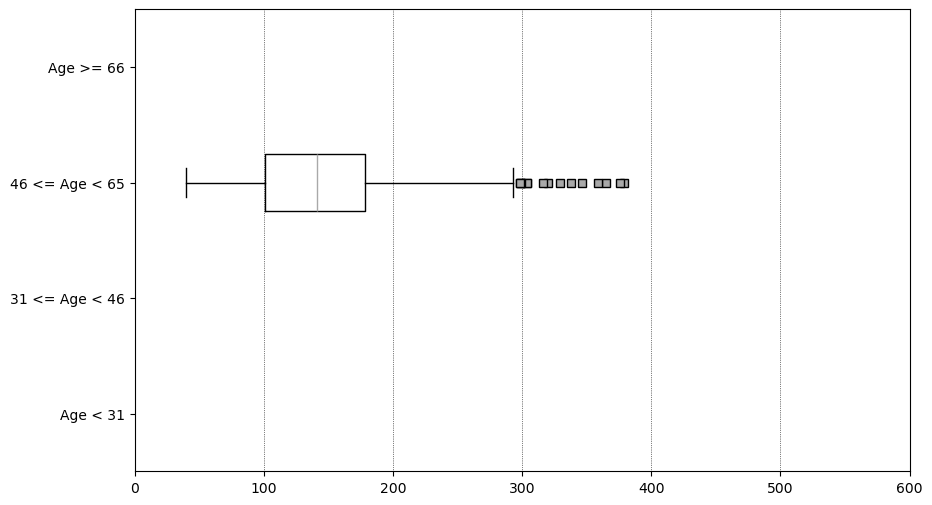

In [54]:
age_vs_measurement_plot_data = [df_glucose_young['Measurement'], df_glucose_young_adult['Measurement'], df_glucose_adult['Measurement'], df_glucose_elders['Measurement']]
darkgray_square = dict(markerfacecolor='darkgray', marker='s')

fig, ax = plt.subplots(figsize=(10,6))

bp = ax.boxplot(age_vs_measurement_plot_data, vert=False, flierprops=darkgray_square, widths=0.5)

for median in bp['medians']:
    median.set_color('darkgray')

x_ticks_values = np.arange(0, 601, 100)
x_ticks_labels = list(map(str, x_ticks_values))
x_ticks = ax.xaxis.set_ticks(x_ticks_values)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_labels = ax.yaxis.set_ticklabels(['Age < 31', '31 <= Age < 46', '46 <= Age < 65', 'Age >= 66'])

ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')

plt.show()

### Percentage of measurements per glucose levels ranges and age

In [55]:
def calc_ranges(df_measurements:pd.DataFrame) -> []:
    too_low_glucose_serie = df_measurements[df_measurements['Measurement'] < 54]['Measurement'].shape[0] # glucose < 54
    low_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 54) & (df_measurements['Measurement'] <= 69)]['Measurement'].shape[0] # 54 <= glucose <= 69
    ok_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 70) & (df_measurements['Measurement'] <= 180)]['Measurement'].shape[0] # 70 <= glucose <= 180
    high_glucose_serie = df_measurements[(df_measurements['Measurement'] >= 181) & (df_measurements['Measurement'] <= 250)]['Measurement'].shape[0] # 181 <= glucose < 250
    too_high_glucose_serie = df_measurements[df_measurements['Measurement'] > 250]['Measurement'].shape[0] # glucose >= 250
    
    return [too_low_glucose_serie, low_glucose_serie, ok_glucose_serie, high_glucose_serie, too_high_glucose_serie]

In [56]:
young_values = calc_ranges(df_glucose_young)
young_adults_values = calc_ranges(df_glucose_young_adult)
adults_values = calc_ranges(df_glucose_adult)
elder_values = calc_ranges(df_glucose_elders)

# Create a 2D NumPy array from the lists
array2d = np.array([young_values, young_adults_values, adults_values, elder_values])


#### Stacked bar graph

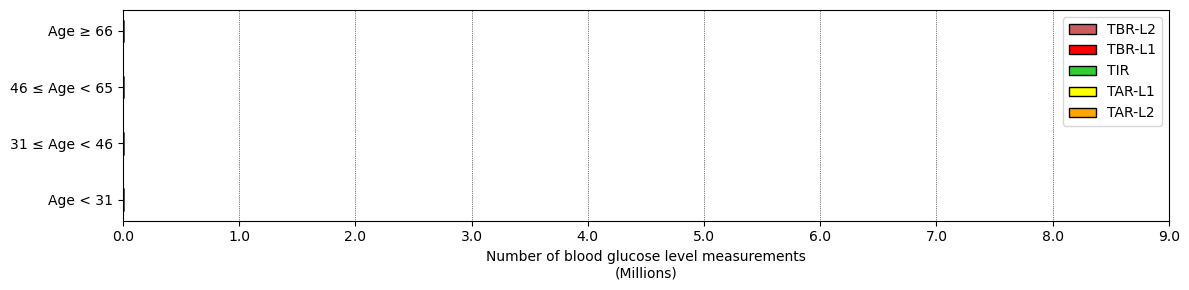

In [57]:
categories = ['Age < 31', '31 ≤ Age < 46', '46 ≤ Age < 65', 'Age ≥ 66']
young_values = array2d[0, :].tolist()
young_adults_values = array2d[1, :].tolist()
adults_values = array2d[2, :].tolist()
elder_values = array2d[3, :].tolist()

fig = plt.figure(figsize =(12, 3), tight_layout = True)
ax = fig.add_subplot(111)

# Combine all values into a single NumPy array
all_values = np.array([young_values, young_adults_values, adults_values, elder_values]).T

# Calculate the positions for the bars
y = np.arange(len(categories))

# Create the stacked bar graph
range_labels = ['TBR-L2', 'TBR-L1', 'TIR', 'TAR-L1', 'TAR-L2']
bar_colors = ['indianred', 'red', 'limegreen', 'yellow', 'orange']
ax.barh(y, all_values[0], label=range_labels[0], edgecolor = "black", height=0.4, color=bar_colors[0])
ax.grid(axis='x', linestyle=':', linewidth='0.5', color='black')

for i in range(1, len(all_values)):
    ax.barh(y, all_values[i], left=np.sum(all_values[:i], axis=0), label=range_labels[i], color=bar_colors[i], height=0.4, edgecolor = "black")

x_title = ax.set_xlabel('Number of blood glucose level measurements\n(Millions)')

x_ticks_values = np.arange(0, 9000001, 1000000)
x_ticks_labels = list(map(str, x_ticks_values/1000000))
x_ticks = ax.xaxis.set_ticks(x_ticks_values)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

lim = ax.set_xlim(xmax=9000000)

ax.set_yticks(y)
ax.set_yticklabels(categories)

legend = ax.legend()

plt.show()

## Date and Measurement
### Number of measurements by year

In [59]:
years = ['2018', '2019', '2020', '2021', '2022']
year_number_list = []

for current_year in years:
    # .sum() suma todos los True (1s) sin lanzar KeyError si no hay ninguno
    current_number = (df_glucose_measurements['Measurement_date'].astype(str).str[:4] == current_year).sum()
    print('Measurements in', current_year, current_number)
    year_number_list.append(current_number)

Measurements in 2018 0
Measurements in 2019 0
Measurements in 2020 1000
Measurements in 2021 0
Measurements in 2022 0


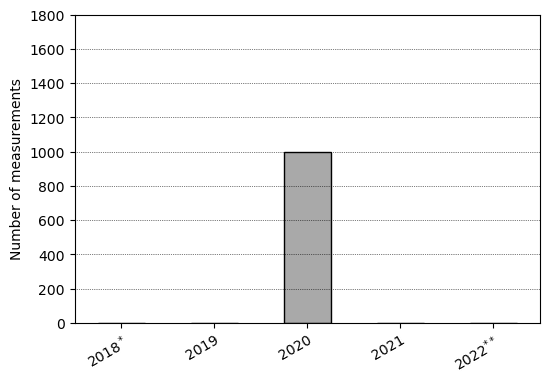

In [72]:
years[0] = '2018$^*$'
years[4] = '2022$^{**}$'
series_measurements_by_year = pd.Series(data=year_number_list, index=years)

ax = series_measurements_by_year.plot(kind='bar', figsize=(6,4), color='darkgray', edgecolor="black")
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')
ax.set_xticklabels(ax.get_xticklabels() , rotation = 30, ha='right', rotation_mode='anchor')

y_ticks_values = np.arange(0, 2000, 200)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

y_title = ax.set_ylabel('Number of measurements')


$^*$ Since January 6th. $^{**}$ Until March 21st.

### Number of glucose levels measurements per day

In [61]:
start_date = df_glucose_measurements['Measurement_date'].min()
end_date = df_glucose_measurements['Measurement_date'].max()

arr_dates = pd.date_range(start_date, end_date, freq='D').values

In [62]:
arr_zeros_glucose = np.zeros(arr_dates.size, dtype=np.int32)

series_dates_and_glucose_values = pd.Series(index=arr_dates, data=arr_zeros_glucose)

for ith_date in series_dates_and_glucose_values.index:
    ith_str_date = ith_date.date().strftime('%Y-%m-%d')
    current_day_measurement_number = df_glucose_measurements[df_glucose_measurements['Measurement_date'] == ith_str_date].shape[0]
    series_dates_and_glucose_values[ith_date] = current_day_measurement_number
    print(ith_str_date + ' -> ' + str(current_day_measurement_number))    

2020-06-09 -> 20
2020-06-10 -> 96
2020-06-11 -> 95
2020-06-12 -> 97
2020-06-13 -> 96
2020-06-14 -> 95
2020-06-15 -> 95
2020-06-16 -> 96
2020-06-17 -> 96
2020-06-18 -> 96
2020-06-19 -> 96
2020-06-20 -> 22


### Number of patients per day

In [63]:
arr_zeros_participants = np.zeros(arr_dates.size, dtype=np.int32)
series_dates_and_patient_number = pd.Series(index=arr_dates, data=arr_zeros_participants)

for ith_date in series_dates_and_patient_number.index:
    ith_str_date = ith_date.date().strftime('%Y-%m-%d')
    current_day_participant_number = df_glucose_measurements[df_glucose_measurements['Measurement_date'] == ith_str_date]['Patient_ID'].unique().size
    series_dates_and_patient_number[ith_date] = current_day_participant_number
    print(ith_str_date + ' -> ' + str(current_day_participant_number))


2020-06-09 -> 1
2020-06-10 -> 1
2020-06-11 -> 1
2020-06-12 -> 1
2020-06-13 -> 1
2020-06-14 -> 1
2020-06-15 -> 1
2020-06-16 -> 1
2020-06-17 -> 1
2020-06-18 -> 1
2020-06-19 -> 1
2020-06-20 -> 1


### Plot of the two times series

In [64]:
fig = plt.figure(figsize =(12, 6), tight_layout = True)
ax1 = fig.add_subplot(111)

delay = 0

ax1.plot(series_dates_and_glucose_values[:series_dates_and_glucose_values.size - delay].index, series_dates_and_glucose_values[:series_dates_and_glucose_values.size - delay].values, color='blue')
ax1.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

date_list = pd.date_range(start_date, end_date, freq='6M').tolist()
date_series = pd.Series(date_list)
date_series = date_series.apply(lambda x: x.date())

bins_x = date_series
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax1.xaxis.set_ticks(bins_x)
x_labels = ax1.xaxis.set_ticklabels(x_ticks_labels)

y_ticks_values = np.arange(0, 60001, 10000)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax1.yaxis.set_ticks(y_ticks_values)
y_labels = ax1.yaxis.set_ticklabels(y_ticks_labels)

plt.yticks(color='blue')

y_title = ax1.set_ylabel('Number of blood glucose level measurements', color='blue')
x_title = ax1.set_xlabel('Date')

ax2 = ax1.twinx()

ax2.plot(series_dates_and_patient_number[:series_dates_and_patient_number.size - delay].index, series_dates_and_patient_number[:series_dates_and_patient_number.size - delay].values, color='red')
ax2.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_title = ax2.set_ylabel('Number of patients', color='red')

plt.yticks(color='red')

y_ticks_values = np.arange(0, 601, 100)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax2.yaxis.set_ticks(y_ticks_values)
y_labels = ax2.yaxis.set_ticklabels(y_ticks_labels)

lim = ax1.set_ylim(ymin=0, ymax=60000)
lim = ax2.set_ylim(ymin=0, ymax=600)
lim = ax2.set_ylim(ymin=0)
lim = ax1.set_xlim(xmin=datetime.date(2018,1,6), xmax=datetime.date(2022,3,15))

plt.show()

/tmp/ipykernel_50014/3240873195.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  date_list = pd.date_range(start_date, end_date, freq='6M').tolist()


TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

<Figure size 1200x600 with 2 Axes>

## Gaps distribution

### Concat times columns and converted to datetime format

In [65]:
df_glucose_measurements['timestamp'] = df_glucose_measurements['Measurement_date'] + ' ' + df_glucose_measurements['Measurement_time'] 
df_glucose_measurements['timestamp'] = pd.to_datetime(df_glucose_measurements['timestamp'])

### Find difference between measurements by participant

In [66]:
acc_series = pd.Series()
counter = 1
for current_patient in df_glucose_measurements['Patient_ID'].unique():
    df_current_patient = df_glucose_measurements[df_glucose_measurements['Patient_ID'] == current_patient]
    current_diff = df_current_patient['timestamp'].diff()
    acc_series = pd.concat([acc_series, current_diff])
    
    print('Patient ' + str(counter) + ' -->  DONE')
    counter += 1

Patient 1 -->  DONE


/tmp/ipykernel_50014/937100650.py:6: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  acc_series = pd.concat([acc_series, current_diff])


### Convert in series of minutes

In [67]:
acc_series_minutes = acc_series.apply(lambda x: x.total_seconds()/60)


### Series of minutes stats

#### Most common intervals percentages

In [68]:
print((acc_series_minutes.value_counts()[:10]/acc_series_minutes.size*100).round(2))

/tmp/ipykernel_50014/4238938231.py:1: FutureWarning: The behavior of obj[i:j] with a float-dtype index is deprecated. In a future version, this will be treated as positional instead of label-based. For label-based slicing, use obj.loc[i:j] instead
  print((acc_series_minutes.value_counts()[:10]/acc_series_minutes.size*100).round(2))


KeyError: 10

#### Intervals above 17

In [ ]:
print('Number of intervals above 17 minutes:')
print(acc_series_minutes[acc_series_minutes >= 18].size)

print()

print('Percentage of intervals above 17 minutes of all measurments:')
print(round(acc_series_minutes[acc_series_minutes >= 18].size/acc_series_minutes.size*100, 2))

Number of intervals above 17 minutes:
215184

Percentage of intervals above 17 minutes of all measurments:
0.95


### Boxplot of the conceptual gaps

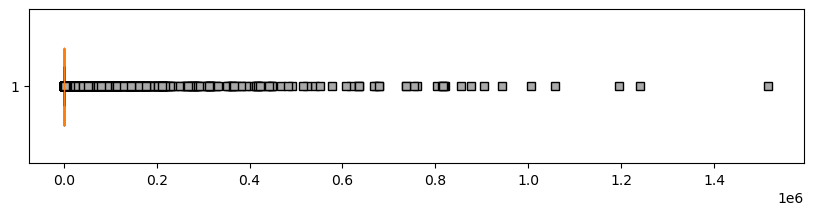

In [ ]:
darkgray_square = dict(markerfacecolor='darkgray', marker='s')
fig, ax = plt.subplots(figsize=(10,2))

acc_series_minutes_filt = acc_series_minutes[(acc_series_minutes >= 18) ]

bp = ax.boxplot(acc_series_minutes_filt, vert=False, flierprops=darkgray_square, widths=0.5)
plt.show()

### Boxplot values

In [ ]:
for key in bp:
    print(f'{key}: {[item.get_xdata() for item in bp[key]]}\n')

whiskers: [array([19., 18.]), array([185., 434.])]

caps: [array([18., 18.]), array([434., 434.])]

boxes: [array([ 19.,  19., 185., 185.,  19.])]

medians: [array([77., 77.])]

fliers: [array([   555., 372810.,   1576., ...,   1217.,    660.,   2326.])]

means: []


### Gaps histogram

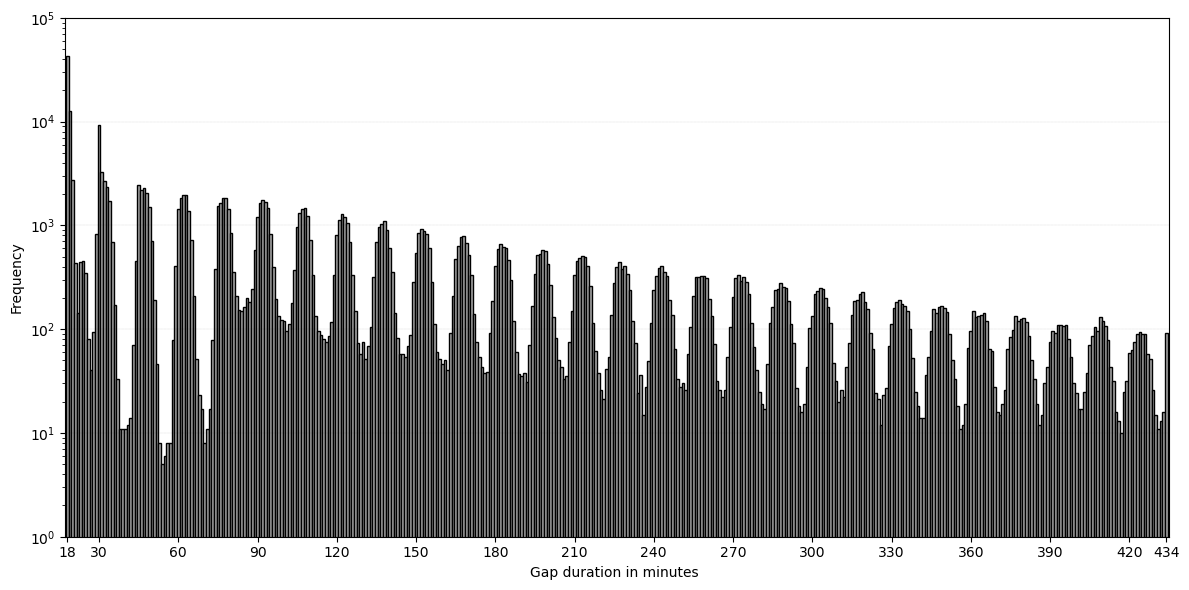

In [ ]:
fig = plt.figure(figsize =(12, 6), tight_layout = True)
ax = fig.add_subplot(111)

range_start = 18
range_end = 434
line_width = 1
logarithmic_version = True


bin_set = np.arange(range_start, range_end + 2, line_width)
n, bins, patches = ax.hist(acc_series_minutes, histtype='bar', align='left', bins=bin_set, color='darkgray', edgecolor = "black", log=logarithmic_version)
ax.grid(axis='y', linestyle=':', linewidth='0.1', color='black')

bins_x = np.arange(30,440,30)

bins_x = np.insert(bins_x, 0, 18)
bins_x = np.append(bins_x, 434)

x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)

y_ticks_values = np.array([10**0, 10**1, 10**2, 10**3, 10**4, 10**5])
y_ticks_labels = list(map(str, ['$10^0$', '$10^1$', '$10^2$', '$10^3$', '$10^4$', '$10^5$']))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

lim = ax.set_xlim(xmin=17,xmax=435)

# lim = ax2.set_ylim(ymin=0, ymax=550)

y_title = ax.set_ylabel('Frequency')

x_title = ax.set_xlabel('Gap duration in minutes ')

plt.show()

# ***Biochemical_parameters.csv***

## Number of records by biochemical parameters name.

### Bar graph

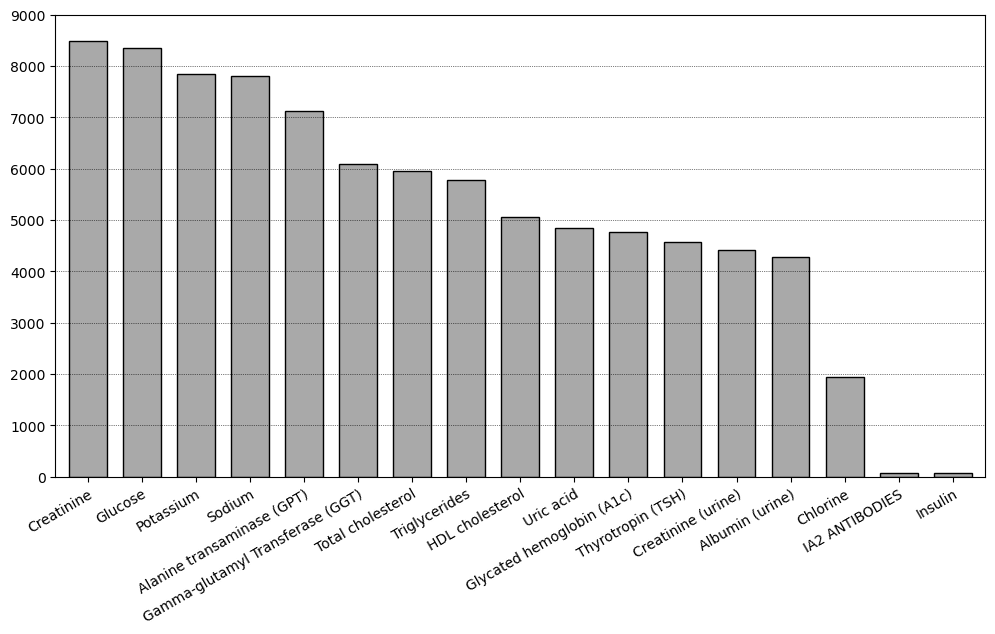

In [ ]:
bioch_params_bar_values = df_biochemical_parameters['Name'].value_counts()

ax = bioch_params_bar_values.plot(kind='bar', figsize=(12,6), color='darkgray', width=0.7, edgecolor="black")
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')
ax.set_xticklabels(ax.get_xticklabels() , rotation = 30, ha='right', rotation_mode='anchor')

y_ticks_values = np.arange(0, 9001, 1000)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

plt.show()

y_title = ax.set_ylabel('Number of records')

## Table of the summary of statistics of the number of biochemical parameters per patient.

In [ ]:
patient_list = df_patient_info['Patient_ID'].unique()
parameter_list = df_biochemical_parameters['Name'].unique()

long_patient_list = np.repeat(patient_list, 17)

long_parm_list = np.tile(parameter_list, (736))


### Dataframe to fill
With the data of the number of biochemical parameters per type per patient

In [ ]:
df_bio_param_report = pd.DataFrame({'Patient_ID':long_patient_list, 'Name':long_parm_list})
df_bio_param_report['sum'] = 0

### Get number of biochemical parameters per patient 

In [ ]:
for current_index in range(0, df_bio_param_report.shape[0]):
    current_patient = df_bio_param_report.loc[current_index, 'Patient_ID']
    current_bio_param = df_bio_param_report.loc[current_index, 'Name']
    df_bio_param_report.loc[current_index, 'sum'] = df_biochemical_parameters[(df_biochemical_parameters['Patient_ID'] == current_patient) & (df_biochemical_parameters['Name'] == current_bio_param)].shape[0]    


In [ ]:
df_table_general = df_bio_param_report.drop(columns=['Patient_ID']).groupby('Name').agg(['mean', 'std', 'median', 'min', 'max', 'sum']).reset_index()
df_table_general = df_table_general.round(2)
df_table_general.columns = ['Name', 'Mean', 'STD', 'Median', 'Minimum', 'Maximum', 'Total']
df_table_general

,Name,Mean,STD,Median,Minimum,Maximum,Total
0,Alanine transaminase (GPT),9.69,8.85,8.0,0,90,7134
1,Albumin (urine),5.82,2.88,6.0,0,21,4283
2,Chlorine,2.63,6.40,1.0,0,74,1935
3,Creatinine,11.54,12.05,9.0,0,115,8495
4,Creatinine (urine),5.99,3.15,6.0,0,27,4412
5,Gamma-glutamyl Transferase (GGT),8.27,7.68,7.0,0,89,6085
6,Glucose,11.34,11.63,9.0,0,111,8349
7,Glycated hemoglobin (A1c),6.49,2.76,7.0,0,16,4776
8,HDL cholesterol,6.88,3.48,7.0,0,26,5062
9,IA2 ANTIBODIES,0.09,0.30,0.0,0,2,66


In [ ]:
df_values_table = df_biochemical_parameters.drop(columns=['Patient_ID', 'Reception_date']).groupby('Name').agg(['mean', 'std','median', 'min', 'max']).reset_index()
df_values_table = df_values_table.round(2)
df_values_table.columns = ['Name', 'Mean', 'STD', 'Median', 'Minimum', 'Maximum']
df_values_table['Total'] = df_table_general['Total']
df_values_table

,Name,Mean,STD,Median,Minimum,Maximum,Total
0,Alanine transaminase (GPT),26.98,44.62,19.00,-4.00,868.00,7134
1,Albumin (urine),4.86,26.56,0.70,0.01,992.20,4283
2,Chlorine,102.96,5.34,103.00,76.00,136.00,1935
3,Creatinine,1.04,0.95,0.80,0.15,11.55,8495
4,Creatinine (urine),114.14,66.80,101.41,2.00,543.46,4412
5,Gamma-glutamyl Transferase (GGT),43.80,113.55,19.00,5.00,2051.00,6085
6,Glucose,163.04,85.40,146.00,10.00,979.00,8349
7,Glycated hemoglobin (A1c),7.82,1.39,7.60,4.00,18.00,4776
8,HDL cholesterol,56.63,14.37,55.00,7.00,137.00,5062
9,IA2 ANTIBODIES,409.64,1237.70,1.15,0.21,6446.74,66


## Distribution of the values of the most commonly measured biochemical parameters.

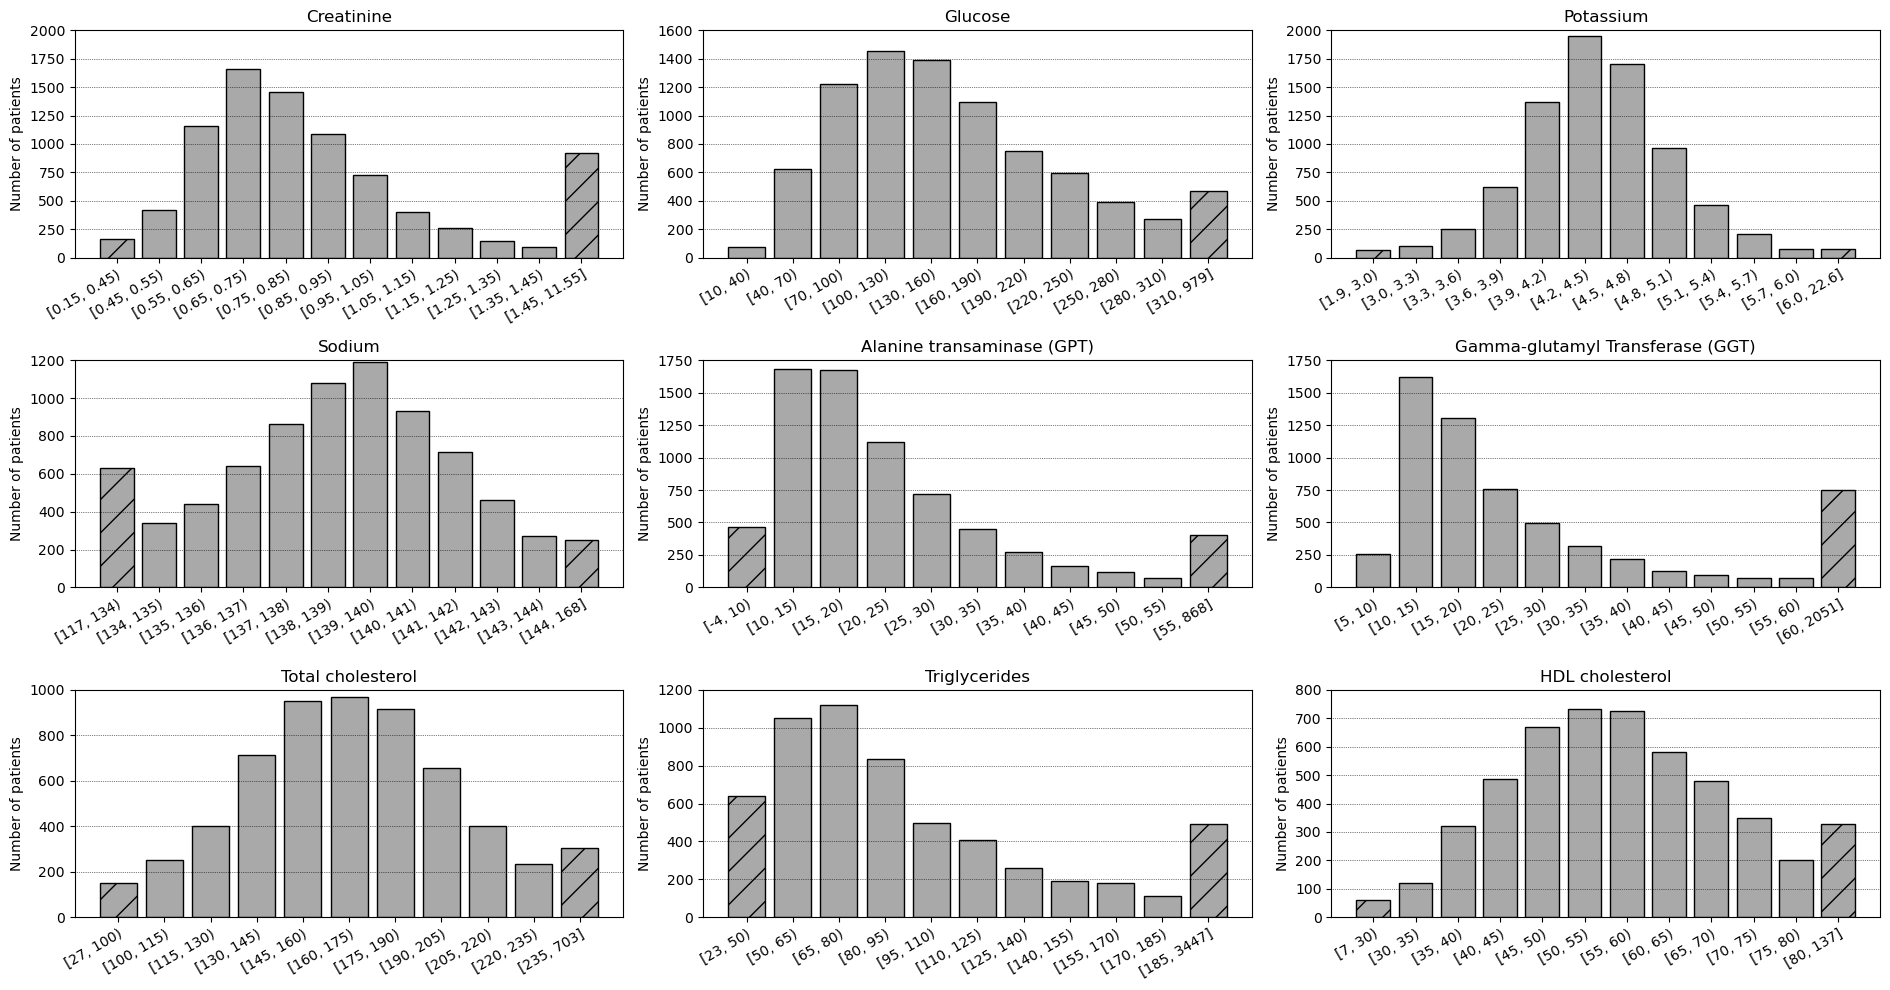

In [ ]:
bioch_params_common = bioch_params_bar_values[:9].index.values

fig = plt.figure(figsize =(19, 10), tight_layout = True)

# VALUE 0 ---------------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[0]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,1)

x_values = np.arange(0.45, 1.46, 0.1)
x_values = np.insert(x_values, 0, 0.15)
x_values = np.append(x_values, 11.55)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = np.round(x_values[x_ith], 2)
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = np.round(x_values[x_ith], 2)

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray', hatch=['/','','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0,2001, 250)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

title = ax.set_title(bioch_params_common[0])
y_title = ax.set_ylabel('Number of patients')

# VALUE 1 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[1]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,2)

x_values = np.arange(10, 311, 30)
x_values = np.append(x_values, 979)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = x_values[x_ith]
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = x_values[x_ith]

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray',hatch=['','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0,1601, 200)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

title = ax.set_title(bioch_params_common[1])
y_title = ax.set_ylabel('Number of patients')

# VALUE 2 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[2]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,3)

x_values = np.arange(3.0, 6.01, 0.3)
x_values = np.insert(x_values, 0,1.9)
x_values = np.append(x_values, 22.6)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = np.round(x_values[x_ith], 2)
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = np.round(x_values[x_ith], 2)

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray',hatch=['/','','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0,2001, 250)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

lim = ax.set_ylim(ymax=2000)

title = ax.set_title(bioch_params_common[2])
y_title = ax.set_ylabel('Number of patients')

# VALUE 3 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[3]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,4)

x_values = np.arange(134, 145, 1)
x_values = np.insert(x_values, 0,117)
x_values = np.append(x_values, 168)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = np.round(x_values[x_ith], 2)
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = np.round(x_values[x_ith], 2)

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray',hatch=['/','','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

lim = ax.set_ylim(ymax=1200)

title = ax.set_title(bioch_params_common[3])
y_title = ax.set_ylabel('Number of patients')

# VALUE 4 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[4]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,5)

x_values = np.arange(10, 56, 5)
x_values = np.insert(x_values, 0, -4)
x_values = np.append(x_values, 868)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = np.round(x_values[x_ith], 2)
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = np.round(x_values[x_ith], 2)

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray',hatch=['/','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

lim = ax.set_ylim(ymax=1750)

title = ax.set_title(bioch_params_common[4])
y_title = ax.set_ylabel('Number of patients')

# VALUE 5 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[5]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,6)

x_values = np.arange(5, 61, 5)
x_values = np.append(x_values, 2051)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = x_values[x_ith]
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = x_values[x_ith]

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray',hatch=['','','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0,1751, 250)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

title = ax.set_title(bioch_params_common[5])
y_title = ax.set_ylabel('Number of patients')

# VALUE 6 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[6]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,7)

x_values = np.arange(100, 250, 15)
x_values = np.insert(x_values, 0, 27)
x_values = np.append(x_values, 703)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = x_values[x_ith]
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = x_values[x_ith]

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray', hatch=['/','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

lim = ax.set_ylim(ymax=1000)

title = ax.set_title(bioch_params_common[6])
y_title = ax.set_ylabel('Number of patients')

# VALUE 7 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[7]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,8)

x_values = np.arange(50, 200, 15)
x_values = np.insert(x_values, 0, 23)
x_values = np.append(x_values, 3447)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = x_values[x_ith]
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = x_values[x_ith]

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray', hatch=['/','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0,1201, 200)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

title = ax.set_title(bioch_params_common[7])
y_title = ax.set_ylabel('Number of patients')

# VALUE 8 ------------------------------------------------------------------------------
current_filter = df_biochemical_parameters['Name'] == bioch_params_common[8]
series_current = df_biochemical_parameters[current_filter]['Value']

ax = fig.add_subplot(3,3,9)

x_values = np.arange(30, 85, 5)
x_values = np.insert(x_values, 0, 7)
x_values = np.append(x_values, 137)

height_val = np.array([])
x_lab = np.array([])
inf = x_values[0]
for x_ith in range(1, x_values.size):
    sup = x_values[x_ith]
    current_number = series_current[(series_current >= inf) & (series_current < sup)].size
    height_val = np.append(height_val, current_number)
    x_lab = np.append(x_lab, '[' + str(inf) + ', ' + str(sup) + ')')
    inf = x_values[x_ith]

range_number = len(x_lab)
las_range_length = len(x_lab[range_number - 1])
x_lab[range_number - 1] = (x_lab[range_number - 1][:las_range_length - 1] + ']') # Put a ']' in the last range.

ax.bar(x_lab, height_val, color='darkgray', hatch=['/','','','','','','','','','','','/'], edgecolor = "black")
plt.xticks(rotation = 30, ha='right', rotation_mode='anchor')
ax.grid(axis='y', linestyle=':', linewidth='0.5', color='black')

y_ticks_values = np.arange(0, 801, 100)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

title = ax.set_title(bioch_params_common[8])
y_title = ax.set_ylabel('Number of patients')

# ***Diagnostics.csv***
## Distribution of patients in the top ten diagnoses.

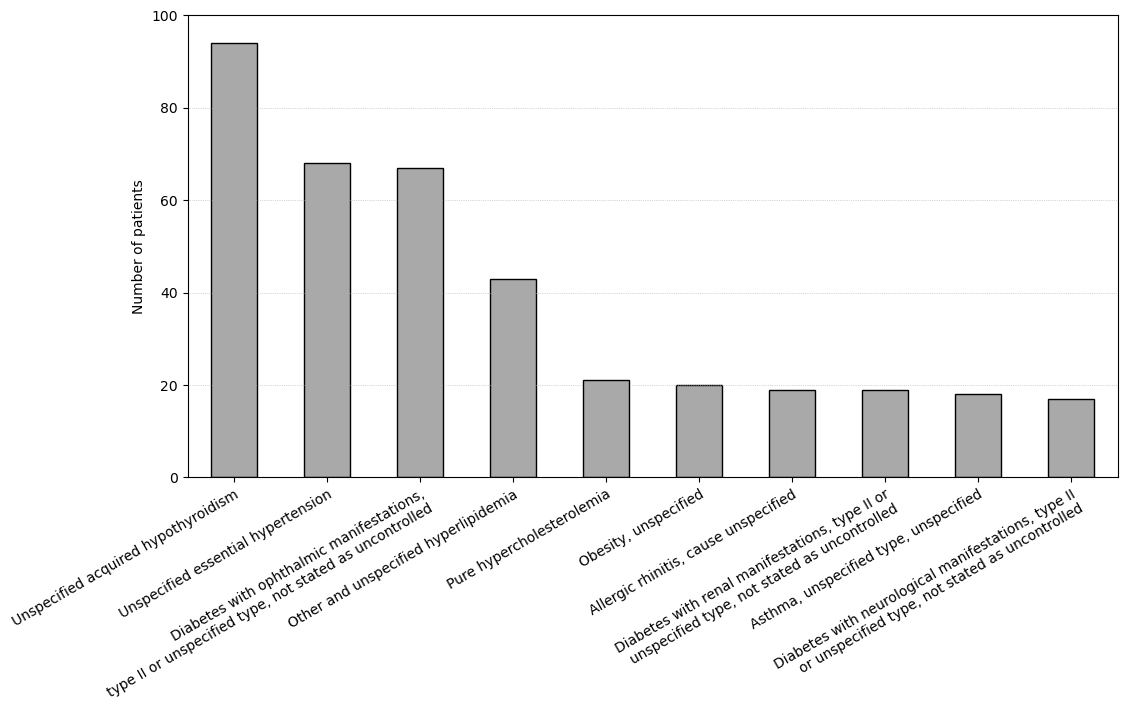

In [ ]:
diagnostics_des = df_diagnostics['Description'].value_counts()
most_common_diag = diagnostics_des.iloc[0:10]

most_common_diag_formatted = most_common_diag.copy()
most_common_diag_formatted.index = ['Unspecified acquired hypothyroidism',
                                   'Unspecified essential hypertension',
                                   'Diabetes with ophthalmic manifestations,\ntype II or unspecified type, not stated as uncontrolled',
                                   'Other and unspecified hyperlipidemia', 'Pure hypercholesterolemia',
                                   'Obesity, unspecified', 'Allergic rhinitis, cause unspecified',
                                   'Diabetes with renal manifestations, type II or\nunspecified type, not stated as uncontrolled',
                                   'Asthma, unspecified type, unspecified',
                                   'Diabetes with neurological manifestations, type II\nor unspecified type, not stated as uncontrolled',
                                    ]

ax = most_common_diag_formatted.plot(kind='bar', figsize=(12, 6), color='darkgray', edgecolor ="black")
ax.grid(axis='y', linestyle=':', linewidth='0.5')
x_labels = ax.set_xticklabels(ax.get_xticklabels() , rotation = 30, ha='right', rotation_mode='anchor')

y_ticks_values = np.arange(0,101, 20)
y_ticks_labels = list(map(str, y_ticks_values))
y_ticks = ax.yaxis.set_ticks(y_ticks_values)
y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

y_title = ax.set_ylabel('Number of patients')